# Práctica 3 — Predicción de deserción estudiantil con clasificadores clásicos
Benjamín Hernández Herrera

**Objetivo.** Al cierre del primer semestre, predecir la situación que tendrá un estudiante al final de la duración normal de su carrera: `graduate`, `dropout` o `enrolled`.

**Datos.** 4424 estudiantes de licenciatura del Instituto Politécnico de Portalegre (Portugal), ciclos 2008/09 a 2018/19 (UCI, dataset 697). Entrenamiento: 3539; prueba: 885 (sin `Target` y sin atributos del segundo semestre).

**Clasificadores comparados:** árbol de decisión, Naive Bayes, kNN, SVM y regresión logística (sin ensambles ni redes neuronales).

**Contenido**
1. Problema y datos
2. Preprocesamiento y validación cruzada común
3. Optimización de hiperparámetros (un apartado por clasificador, con su curva de meseta)
4. Comparación de los cinco clasificadores
5. Matriz de confusión y análisis de la clase `dropout`
6. ¿Conviene esperar al segundo semestre?
7. Clasificador final y predicciones de prueba
8. Discusión y conclusiones

## 1. Problema y datos

In [ ]:
import os, sys, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler,
                                   KBinsDiscretizer, FunctionTransformer)
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV,
                                      cross_val_predict, cross_val_score)
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

try:
    from IPython.display import display
except ImportError:                       # ejecución fuera de Jupyter
    display = print

warnings.filterwarnings("ignore")          # advertencias de convergencia / bins duplicados
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

# ---------------- Configuración ----------------
SEED     = 42
N_FOLDS  = 5
N_ITER   = int(os.environ.get("N_ITER", 60))     # configuraciones por clasificador (>= 50)
DATA_DIR = Path("datos")
OUT_DIR  = Path("salidas"); OUT_DIR.mkdir(exist_ok=True)
PRED_CSV = Path("predicciones.csv")
np.random.seed(SEED)
if N_ITER < 50:
    print(f"AVISO: N_ITER={N_ITER} < 50; la práctica exige al menos 50 configuraciones por clasificador.")

# ---------------- Versiones ----------------
print("Python      :", sys.version.split()[0], "|", platform.platform())
for lib in (np, pd, scipy, sklearn, __import__("matplotlib")):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
numpy       : 2.4.6
pandas      : 2.2.3
scipy       : 1.16.3
sklearn     : 1.6.1
matplotlib  : 3.10.0


In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
train = pd.read_csv(DATA_DIR / "desercion-entrenamiento.csv")
test  = pd.read_csv(DATA_DIR / "desercion-prueba.csv")
train["Target"] = train["Target"].str.strip().str.lower()     # dropout / enrolled / graduate

print("entrenamiento:", train.shape, "| prueba:", test.shape)
print("Valores faltantes -> train:", int(train.isna().sum().sum()), "| prueba:", int(test.isna().sum().sum()))
print("id únicos en prueba:", test["id"].is_unique)

# Atributos disponibles al cierre del primer semestre = columnas presentes en la prueba
FEATURES_1S = [c for c in train.columns if c in test.columns and c not in ("id", "Target")]
FEATURES_2S = [c for c in train.columns if c not in ("id", "Target")]      # incluye 2.º semestre
SECOND_SEM  = [c for c in FEATURES_2S if c not in FEATURES_1S]
assert set(FEATURES_1S) == set(test.columns) - {"id"}, "La prueba tiene columnas que no están en entrenamiento"
print(f"\nAtributos 1.er semestre: {len(FEATURES_1S)} | extra del 2.º semestre (solo en entrenamiento): {len(SECOND_SEM)}")
print(*SECOND_SEM, sep="\n  - ")

X, X2, y = train[FEATURES_1S], train[FEATURES_2S], train["Target"]
LABELS = sorted(y.unique())
print("\nClases:", LABELS)

entrenamiento: (3539, 38) | prueba: (885, 31)
Valores faltantes -> train: 0 | prueba: 0
id únicos en prueba: True

Atributos 1.er semestre: 30 | extra del 2.º semestre (solo en entrenamiento): 6
Curricular units 2nd sem (credited)
  - Curricular units 2nd sem (enrolled)
  - Curricular units 2nd sem (evaluations)
  - Curricular units 2nd sem (approved)
  - Curricular units 2nd sem (grade)
  - Curricular units 2nd sem (without evaluations)

Clases: ['dropout', 'enrolled', 'graduate']


,n,%
Target,,
dropout,1137,32.1
enrolled,635,17.9
graduate,1767,49.9


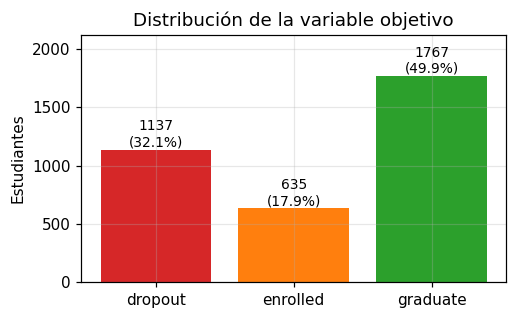

In [ ]:
# Distribución de las clases
cnt = y.value_counts().reindex(LABELS)
dist = pd.DataFrame({"n": cnt, "%": (100 * cnt / cnt.sum()).round(1)})
display(dist)

fig, ax = plt.subplots(figsize=(4.8, 3))
ax.bar(dist.index, dist["n"], color=["C3", "C1", "C2"][:len(dist)])
for i, (n, p) in enumerate(zip(dist["n"], dist["%"])):
    ax.text(i, n, f"{n}\n({p}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, dist["n"].max() * 1.2); ax.set_ylabel("Estudiantes"); ax.set_title("Distribución de la variable objetivo")
fig.tight_layout(); fig.savefig(OUT_DIR / "distribucion_clases.png"); plt.show()

In [ ]:
# Tipo de cada atributo. Varios nominales vienen como enteros: NO deben tratarse como numéricos.
NOMINAL = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARY  = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
           "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
# Resto = numéricos (calificaciones, edad, conteos de unidades curriculares, variables macroeconómicas).
# 'Application order' es ordinal (0-9) y se trata como numérica.
missing = [c for c in NOMINAL + BINARY if c not in FEATURES_2S]
assert not missing, f"Columnas no encontradas (revisa los nombres exactos del CSV): {missing}"

def sel_nominal(df): return [c for c in NOMINAL if c in df.columns]
def sel_binary(df):  return [c for c in BINARY  if c in df.columns]
def sel_numeric(df): return [c for c in df.columns if c not in NOMINAL + BINARY]

tipos = pd.DataFrame({
    "tipo": ["nominal (códigos enteros)"] * len(NOMINAL) + ["binario"] * len(BINARY) + ["numérico"] * len(sel_numeric(X)),
    "atributo": NOMINAL + BINARY + sel_numeric(X)})
resumen = tipos.groupby("tipo")["atributo"].agg(["count", lambda s: ", ".join(s)]).rename(columns={"count": "n", "<lambda_0>": "atributos"})
pd.set_option("display.max_colwidth", 140)
print(resumen.to_string())
print("\nCardinalidad de los nominales (entrenamiento):")
print(X[NOMINAL].nunique().sort_values(ascending=False).to_string())

                            n                                                                                                                                                                                                                                                                                                                                                               atributos
tipo                                                                                                                                                                                                                                                                                                                                                                                                 
binario                     8                                                                                                                                                                                               

### Descripción del problema y de los datos

- **Clases (entrenamiento, n = 3539):** `graduate` 1767 (49.9 %), `dropout` 1137 (32.1 %) y `enrolled` 635 (17.9 %). El desbalance es moderado: `enrolled` es la clase minoritaria, casi tres veces menos frecuente que `graduate`. Por eso se usa **F1 macro** como métrica principal (pondera igual a las tres clases; la exactitud premiaría predecir siempre `graduate`) y se incluye `class_weight` en el espacio de búsqueda de los clasificadores que lo admiten.
- **Atributos:** 30 disponibles al cierre del primer semestre: **9 nominales** codificados como enteros, **8 binarios** y **13 numéricos** (calificaciones, edad, conteos de unidades curriculares del primer semestre y tres variables macroeconómicas). Los nominales tienen cardinalidad alta: ocupación del padre (45 categorías), calificación del padre (32), ocupación de la madre (31), calificación de la madre (26), nacionalidad (18), modo de aplicación, calificación previa y carrera (17 cada una) y estado civil (6). Por eso se codifican con one-hot agrupando las categorías poco frecuentes, en lugar de tratarlos como números. No hay valores faltantes ni en entrenamiento ni en prueba.
- **Información disponible al decidir:** solo los 30 atributos del primer semestre. Los 6 atributos `Curricular units 2nd sem (...)` existen únicamente en el entrenamiento, así que no pueden entrar al modelo final; solo se usan en la sección 6 para estimar cuánto se ganaría esperando.

## 2. Preprocesamiento y validación cruzada común

Todo el preprocesamiento va **dentro de un `Pipeline`**, de modo que cada ajuste (codificación, escalamiento, discretización) se aprende solo con los pliegues de entrenamiento de cada partición y no hay fuga de información hacia validación.

| Clasificador | Nominales | Binarios | Numéricos | Justificación |
|---|---|---|---|---|
| Árbol | One-hot (categorías raras agrupadas) | tal cual | tal cual | Los árboles no dependen de la escala; el one-hot evita imponer un orden falso a códigos como `Course`. |
| Naive Bayes categórico | Ordinal (+1; 0 = desconocida) | tal cual | **Discretizados** (`KBinsDiscretizer`) | `CategoricalNB` necesita atributos discretos. |
| Naive Bayes gaussiano | One-hot | tal cual | tal cual | Supone variables continuas; es la variante alternativa. |
| kNN | One-hot | tal cual | **Estandarizados** | La distancia es sensible a la escala. |
| SVM | One-hot | tal cual | **Estandarizados** | Kernels basados en distancias/productos punto. |
| Regresión logística | One-hot | tal cual | **Estandarizados** | Regularización y convergencia dependen de la escala. |

`OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=...)` agrupa las categorías poco frecuentes (muchas ocupaciones y calificaciones previas tienen pocos casos) y tolera categorías no vistas en validación/prueba. `min_frequency` se incluye en el espacio de búsqueda.

**Validación.** `StratifiedKFold(5, shuffle=True, random_state=42)`: **el mismo objeto de pliegues** para las cinco búsquedas, para la comparación y para la matriz de confusión. Métrica de selección: **F1 macro**.

In [ ]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)   # mismos pliegues para todos

def make_ohe(min_freq=0.01):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)

def make_prep(scale):
    # Nominales -> one-hot | binarios -> sin cambio | numéricos -> estandarizados o sin cambio.
    # Las columnas se eligen con funciones, así el mismo preprocesador funciona con 30 o 36 atributos.
    return ColumnTransformer([
        ("nom", make_ohe(), sel_nominal),
        ("bin", "passthrough", sel_binary),
        ("num", StandardScaler() if scale else "passthrough", sel_numeric),
    ])

def plus_one(a):                      # reserva el código 0 para categorías no vistas en CategoricalNB
    return a + 1

def make_prep_categorical_nb():
    return ColumnTransformer([
        ("nom", Pipeline([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("shift", FunctionTransformer(plus_one))]), sel_nominal),
        ("bin", "passthrough", sel_binary),
        ("num", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"), sel_numeric),
    ])

In [ ]:
RESULTS = {}          # nombre -> dict(search, secs, n_configs, space)

def run_search(name, pipe, space, n_iter=N_ITER):
    t0 = time.perf_counter()
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="f1_macro", cv=cv,
                                random_state=SEED, n_jobs=-1, refit=True, error_score=np.nan)
    search.fit(X, y)
    secs = time.perf_counter() - t0
    n_eval = len(search.cv_results_["params"])
    n_fail = int(np.isnan(search.cv_results_["mean_test_score"]).sum())
    RESULTS[name] = dict(search=search, secs=secs, n_configs=n_eval, space=space)
    i = search.best_index_
    print(f"[{name}] configuraciones evaluadas: {n_eval} (fallidas: {n_fail}) | tiempo de búsqueda: {secs:,.1f} s")
    print(f"[{name}] mejor F1 macro (CV): {search.best_score_:.4f} ± {search.cv_results_['std_test_score'][i]:.4f}")
    print(f"[{name}] mejores hiperparámetros:")
    for k, v in search.best_params_.items():
        print(f"      {k}: {v if not hasattr(v, 'get_params') else type(v).__name__}")
    return search

def plot_plateau(name, param=None, log=False, label=None):
    # Izq.: mejor F1 macro alcanzado vs número de configuraciones (meseta).
    # Der. (opcional): F1 macro de cada configuración vs el hiperparámetro más influyente.
    res = pd.DataFrame(RESULTS[name]["search"].cv_results_)
    s = res["mean_test_score"].to_numpy(dtype=float)
    best = np.maximum.accumulate(np.nan_to_num(s, nan=-np.inf))
    k = np.arange(1, len(s) + 1)
    ncols = 2 if param else 1
    fig, axes = plt.subplots(1, ncols, figsize=(5.6 * ncols, 3.6)); axes = np.atleast_1d(axes)
    ax = axes[0]
    ax.scatter(k, s, s=14, alpha=.45, label="F1 macro de cada configuración")
    ax.plot(k, best, color="C3", lw=2, label="Mejor hasta el momento")
    ax.set_xlabel("Número de configuraciones evaluadas"); ax.set_ylabel("F1 macro (validación)")
    ax.set_title(f"{name}: búsqueda"); ax.legend(fontsize=8, loc="lower right")
    if param:
        col = "param_" + param
        xv = pd.to_numeric(res[col], errors="coerce") if col in res else pd.Series(np.nan, index=res.index)
        ok = xv.notna() & res["mean_test_score"].notna()
        ax = axes[1]; ax.scatter(xv[ok], res.loc[ok, "mean_test_score"], s=16, alpha=.6)
        if log: ax.set_xscale("log")
        ax.set_xlabel(label or param); ax.set_ylabel("F1 macro (validación)"); ax.set_title(f"{name}: F1 vs {label or param}")
    fig.tight_layout(); fig.savefig(OUT_DIR / f"meseta_{name.replace(' ', '_').lower()}.png"); plt.show()

## 3. Optimización de hiperparámetros

Para los cinco clasificadores: `RandomizedSearchCV` con **F1 macro**, los **mismos pliegues** (`cv`), `random_state` fijo y **N_ITER configuraciones** (≥ 50). En cada apartado se declara el espacio de búsqueda y se muestra la gráfica de meseta.

### 3.1 Árbol de decisión

Espacio de búsqueda: `criterion` (gini, entropy, log_loss), `max_depth`, `min_samples_leaf`, **poda por costo-complejidad** `ccp_alpha` (log-uniforme), `class_weight` (None / balanced) y `min_frequency` del one-hot.

[Árbol] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 24.1 s
[Árbol] mejor F1 macro (CV): 0.6439 ± 0.0154
[Árbol] mejores hiperparámetros:
      clf__ccp_alpha: 0.0005019072833961318
      clf__class_weight: balanced
      clf__criterion: entropy
      clf__max_depth: 6
      clf__min_samples_leaf: 29
      prep__nom__min_frequency: 0.03


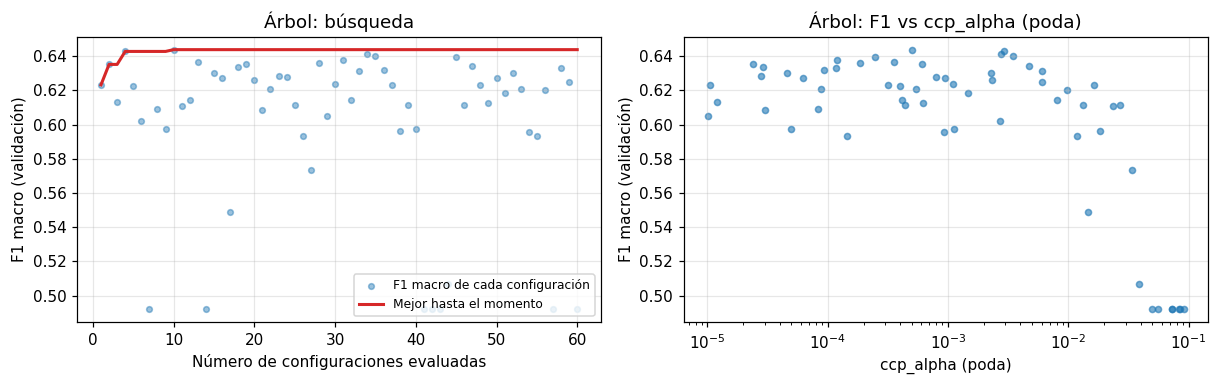

In [ ]:
pipe_tree = Pipeline([("prep", make_prep(scale=False)),
                      ("clf", DecisionTreeClassifier(random_state=SEED))])
space_tree = {
    "clf__criterion":        ["gini", "entropy", "log_loss"],
    "clf__max_depth":        [3, 4, 5, 6, 8, 10, 12, 15, 20, None],
    "clf__min_samples_leaf": randint(1, 41),
    "clf__ccp_alpha":        loguniform(1e-5, 1e-1),
    "clf__class_weight":     [None, "balanced"],
    "prep__nom__min_frequency": [0.005, 0.01, 0.03],
}
run_search("Árbol", pipe_tree, space_tree)
plot_plateau("Árbol", param="clf__ccp_alpha", log=True, label="ccp_alpha (poda)")

### 3.2 Naive Bayes

Dos variantes en el mismo espacio de búsqueda (cada una con su propio preprocesamiento):
- **`CategoricalNB`** con numéricos discretizados: `alpha` (suavizado de Laplace/Lidstone), `n_bins`, `strategy` de discretización y `fit_prior`.
- **`GaussianNB`** sobre one-hot + numéricos: `var_smoothing`.

[Naive Bayes] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 13.0 s
[Naive Bayes] mejor F1 macro (CV): 0.6249 ± 0.0139
[Naive Bayes] mejores hiperparámetros:
      clf: CategoricalNB
      clf__alpha: 2.512779099948728
      clf__fit_prior: False
      prep: ColumnTransformer
      prep__num__n_bins: 4
      prep__num__strategy: quantile
Variante ganadora: CategoricalNB


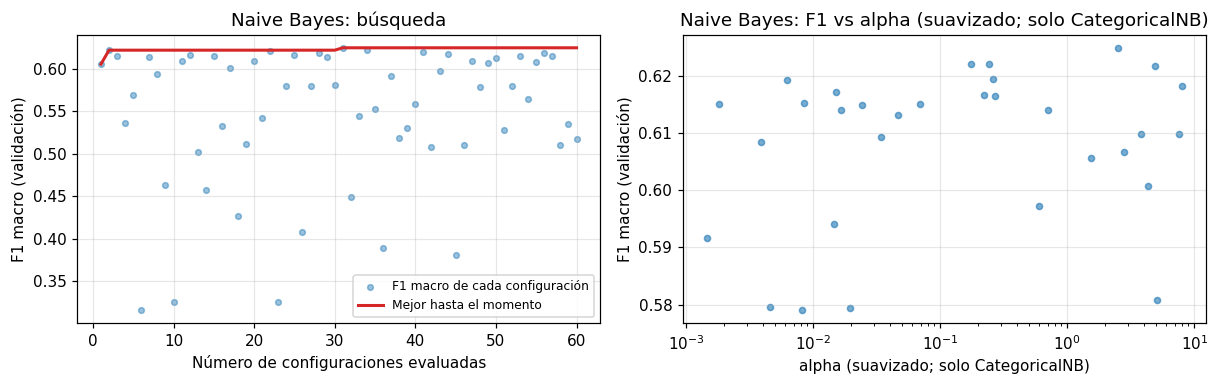

In [ ]:
pipe_nb = Pipeline([("prep", make_prep(scale=False)), ("clf", GaussianNB())])
space_nb = [
    {   # variante categórica
        "prep": [make_prep_categorical_nb()],
        "clf": [CategoricalNB()],
        "clf__alpha": loguniform(1e-3, 1e1),
        "clf__fit_prior": [True, False],
        "prep__num__n_bins": [3, 4, 5, 6, 8, 10],
        "prep__num__strategy": ["quantile", "uniform"],
    },
    {   # variante gaussiana
        "prep": [make_prep(scale=False)],
        "clf": [GaussianNB()],
        "clf__var_smoothing": loguniform(1e-11, 1e-1),
        "prep__nom__min_frequency": [0.005, 0.01, 0.03],
    },
]
run_search("Naive Bayes", pipe_nb, space_nb)
b = RESULTS["Naive Bayes"]["search"].best_params_
print("Variante ganadora:", type(b["clf"]).__name__)
plot_plateau("Naive Bayes", param="clf__alpha", log=True, label="alpha (suavizado; solo CategoricalNB)")

### 3.3 k vecinos más cercanos (kNN)

Espacio: `n_neighbors` (1–80), `weights` (uniform / distance), **distancia** (`euclidean`, `manhattan`, `chebyshev`, `cosine`) y `min_frequency` del one-hot. Numéricos estandarizados.

[kNN] configuraciones evaluadas: 60 (fallidas: 15) | tiempo de búsqueda: 30.5 s
[kNN] mejor F1 macro (CV): 0.5596 ± 0.0268
[kNN] mejores hiperparámetros:
      clf__metric: euclidean
      clf__n_neighbors: 5
      clf__weights: distance
      prep__nom__min_frequency: 0.03


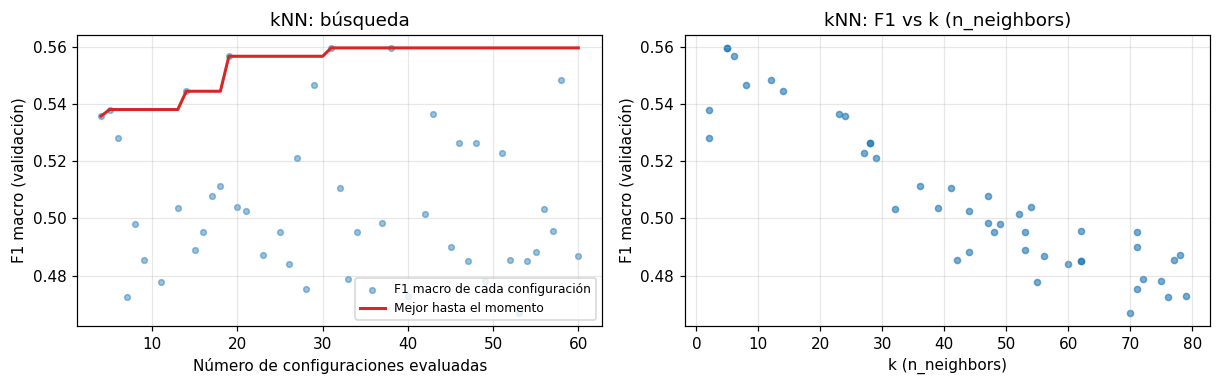

In [ ]:
pipe_knn = Pipeline([("prep", make_prep(scale=True)), ("clf", KNeighborsClassifier())])
space_knn = {
    "clf__n_neighbors": randint(1, 81),
    "clf__weights":     ["uniform", "distance"],
    "clf__metric":      ["euclidean", "manhattan", "chebyshev", "cosine"],
    "prep__nom__min_frequency": [0.005, 0.01, 0.03],
}
run_search("kNN", pipe_knn, space_knn)
plot_plateau("kNN", param="clf__n_neighbors", label="k (n_neighbors)")

### 3.4 Máquinas de soporte vectorial (SVM)

Espacio: `kernel` (linear, rbf, poly, sigmoid), `C` (log-uniforme 1e-2–30), `gamma` (log-uniforme 1e-4–1; no aplica al kernel lineal), `degree` (2 o 3, solo kernel poly), `class_weight` (None / balanced) y `min_frequency`. Numéricos estandarizados. Se limita `max_iter` (100 000) y `C` ≤ 30 para acotar el tiempo de las configuraciones que convergen muy lento (kernel lineal/poly con `C` grande); una configuración que no converge obtiene un F1 bajo y simplemente no se elige.

[SVM] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 284.3 s
[SVM] mejor F1 macro (CV): 0.6757 ± 0.0084
[SVM] mejores hiperparámetros:
      clf__C: 1.6315698516262178
      clf__class_weight: balanced
      clf__degree: 3
      clf__gamma: 0.022881441989554118
      clf__kernel: rbf
      prep__nom__min_frequency: 0.005


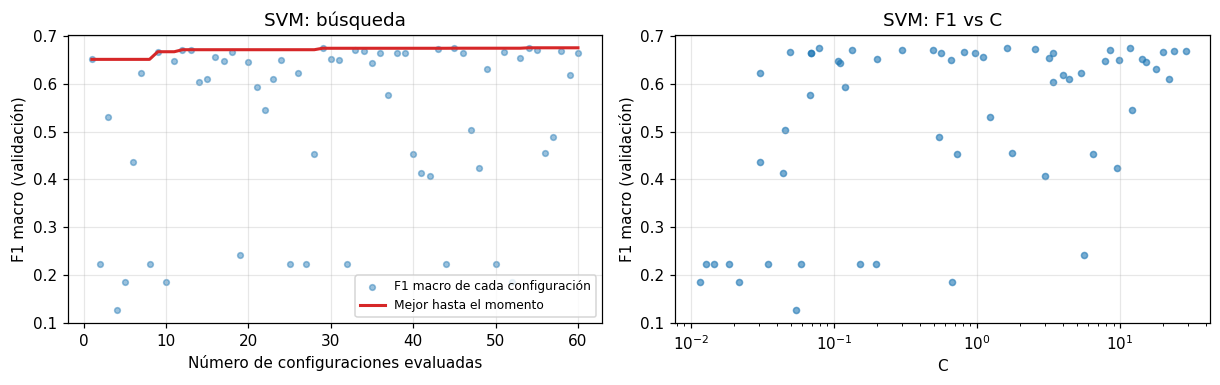

In [ ]:
pipe_svm = Pipeline([("prep", make_prep(scale=True)), ("clf", SVC(random_state=SEED, cache_size=1000, max_iter=100_000))])
space_svm = {
    "clf__kernel":       ["linear", "rbf", "poly", "sigmoid"],
    "clf__C":            loguniform(1e-2, 3e1),
    "clf__gamma":        loguniform(1e-4, 1e0),
    "clf__degree":       [2, 3],
    "clf__class_weight": [None, "balanced"],
    "prep__nom__min_frequency": [0.005, 0.01, 0.03],
}
run_search("SVM", pipe_svm, space_svm)
plot_plateau("SVM", param="clf__C", log=True, label="C")

### 3.5 Regresión logística

Espacio: `C` (log-uniforme 1e-3–1e2), **tipo de regularización** (L1, L2 o elastic net; solver `saga`, que admite las tres), `class_weight` (None / balanced) y `min_frequency`. Numéricos estandarizados.

La API de `LogisticRegression` cambió en versiones recientes de scikit-learn (el parámetro `penalty` quedó obsoleto y la regularización se controla con `l1_ratio`: 0 = L2, 1 = L1, intermedio = elastic net). La celda detecta la versión y arma el espacio correcto.

[Regresión logística] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 360.9 s
[Regresión logística] mejor F1 macro (CV): 0.6792 ± 0.0106
[Regresión logística] mejores hiperparámetros:
      clf__C: 0.137310924682403
      clf__class_weight: balanced
      clf__l1_ratio: 0.7
      clf__penalty: elasticnet
      prep__nom__min_frequency: 0.005


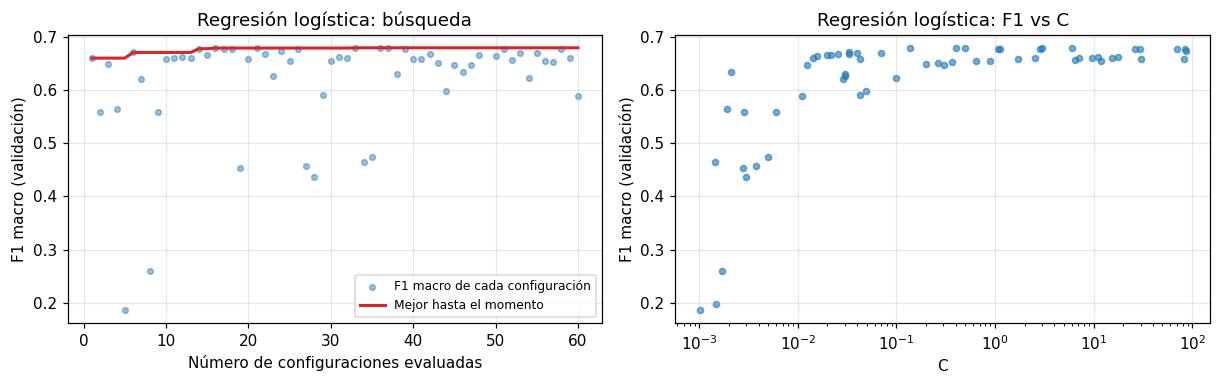

In [ ]:
NEW_LR_API = LogisticRegression().get_params().get("penalty", "deprecated") == "deprecated"
common_lr = {
    "clf__C":            loguniform(1e-3, 1e2),
    "clf__class_weight": [None, "balanced"],
    "prep__nom__min_frequency": [0.005, 0.01, 0.03],
}
if NEW_LR_API:      # l1_ratio: 0 -> L2, 1 -> L1, intermedio -> elastic net
    space_lr = {**common_lr, "clf__l1_ratio": [0.0, 0.15, 0.3, 0.5, 0.7, 0.85, 1.0]}
else:
    space_lr = [{**common_lr, "clf__penalty": ["l2"]},
                {**common_lr, "clf__penalty": ["l1"]},
                {**common_lr, "clf__penalty": ["elasticnet"], "clf__l1_ratio": [0.15, 0.3, 0.5, 0.7, 0.85]}]

pipe_lr = Pipeline([("prep", make_prep(scale=True)),
                    ("clf", LogisticRegression(solver="saga", max_iter=1000, tol=1e-3, random_state=SEED))])
run_search("Regresión logística", pipe_lr, space_lr)
plot_plateau("Regresión logística", param="clf__C", log=True, label="C")

### Lectura de las gráficas de meseta

En los cinco clasificadores, la curva de "mejor hasta el momento" quedó plana antes de agotar las 60 configuraciones, así que la búsqueda llegó a una meseta (con la salvedad de kNN, ver abajo).

- **Árbol:** la meseta (≈ 0.644) se alcanza hacia la configuración 10 y no vuelve a moverse. En la poda, el F1 se mantiene entre ≈ 0.60 y 0.64 para `ccp_alpha` desde 1e-5 hasta ≈ 1e-2 y se desploma por encima de ≈ 2e-2 (el árbol se poda hasta casi un tocón y el F1 cae a ≈ 0.49). La mejor configuración usa poca poda (`ccp_alpha` ≈ 5e-4), profundidad 6, `min_samples_leaf` = 29 y `class_weight="balanced"`: el árbol necesita regularizarse, pero no demasiado.
- **Naive Bayes:** la meseta (≈ 0.625) se alcanza casi de inmediato (configuración 2–3, con un pequeño avance en la 31). Ganó la variante **categórica** (`CategoricalNB`, 4 bins por cuantiles, `fit_prior=False`). El suavizado `alpha` casi no importa en el rango 0.1–8 (F1 entre 0.60 y 0.625); solo valores muy pequeños (< 0.01) empeoran un poco.
- **kNN:** la curva sube por escalones hasta la configuración ≈ 31 (≈ 0.560) y después ya no mejora. El F1 baja al crecer `k` (el mejor es k = 5 con ponderación por distancia), lo que indica que la información útil es muy local y que los vecinos lejanos agregan ruido. **Aviso:** 15 de las 60 configuraciones fallaron (25 %), por lo que kNN solo tiene 45 configuraciones válidas; ver las limitaciones en la sección 8.
- **SVM:** la meseta (≈ 0.676) se alcanza en la configuración ≈ 29. Hay muchas configuraciones con F1 ≈ 0.2 (se degeneran a predecir casi una sola clase), sobre todo con `C` pequeño; con `C` ≳ 0.5 la mayoría rinde entre 0.65 y 0.68, es decir, el SVM es poco sensible a `C` una vez que está en esa zona. La mejor configuración usa kernel RBF, `C` ≈ 1.6, `gamma` ≈ 0.023 y `class_weight="balanced"`.
- **Regresión logística:** la meseta (≈ 0.679) se alcanza en la configuración ≈ 14. El F1 crece con `C` hasta ≈ 0.05–0.1 (con regularización muy fuerte el modelo subajusta, F1 < 0.6) y luego se queda plano entre 0.65 y 0.68 hasta `C` = 100. Ganó **elastic net** (`l1_ratio` = 0.7) con `C` ≈ 0.14 y `class_weight="balanced"`.

En todos los casos `class_weight="balanced"` quedó en la mejor configuración de los clasificadores que lo admiten (árbol, SVM y regresión logística), lo que es coherente con el desbalance de clases.

## 4. Comparación de los cinco clasificadores

Métrica principal: **F1 macro**, media y desviación estándar entre los 5 pliegues (los mismos para todos), calculadas para la mejor configuración de cada búsqueda. Sensibilidad (recall) y especificidad por clase, a partir de predicciones de validación cruzada (`cross_val_predict` con los mismos pliegues). Tiempo = duración de la búsqueda completa.

> Ojo: el F1 de la **mejor** configuración de una búsqueda es ligeramente optimista, porque se eligió precisamente por ser la mejor en esos pliegues. Es válido para comparar entre clasificadores (todos pasan por el mismo proceso), pero no es una estimación imparcial del desempeño en prueba.

In [ ]:
def sens_spec(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    out = {}
    for i, l in enumerate(labels):
        tp = cm[i, i]; fn = cm[i].sum() - tp; fp = cm[:, i].sum() - tp; tn = cm.sum() - tp - fn - fp
        out[f"sens_{l}"] = tp / (tp + fn) if (tp + fn) else np.nan
        out[f"esp_{l}"]  = tn / (tn + fp) if (tn + fp) else np.nan
    return out

PRED_CV = {}      # predicciones de validación cruzada de cada mejor modelo
rows = []
for name, r in RESULTS.items():
    s = r["search"]; i = s.best_index_
    PRED_CV[name] = cross_val_predict(clone(s.best_estimator_), X, y, cv=cv, n_jobs=-1)
    rows.append({"clasificador": name,
                 "F1 macro (media)": s.cv_results_["mean_test_score"][i],
                 "F1 macro (desv. est.)": s.cv_results_["std_test_score"][i],
                 **sens_spec(y, PRED_CV[name], LABELS),
                 "configs": r["n_configs"], "tiempo búsqueda (s)": r["secs"]})
comp = pd.DataFrame(rows).set_index("clasificador").sort_values("F1 macro (media)", ascending=False)
comp.round(4).to_csv(OUT_DIR / "comparacion_clasificadores.csv")
comp.round(3)

,F1 macro (media),F1 macro (desv. est.),sens_dropout,esp_dropout,sens_enrolled,esp_enrolled,sens_graduate,esp_graduate,configs,tiempo búsqueda (s)
clasificador,,,,,,,,,,
Regresión logística,0.679,0.011,0.691,0.918,0.575,0.825,0.793,0.840,60,360.869
SVM,0.676,0.008,0.661,0.933,0.578,0.817,0.808,0.830,60,284.251
Árbol,0.644,0.015,0.624,0.935,0.570,0.771,0.763,0.832,60,24.146
Naive Bayes,0.625,0.014,0.697,0.843,0.487,0.827,0.715,0.834,60,12.998
kNN,0.560,0.027,0.573,0.900,0.217,0.921,0.873,0.582,60,30.482


Árbol: ccp_alpha=0.0005019072833961318, class_weight=balanced, criterion=entropy, max_depth=6, min_samples_leaf=29, min_frequency=0.03
Naive Bayes: clf=CategoricalNB, alpha=2.512779099948728, fit_prior=False, prep=ColumnTransformer, n_bins=4, strategy=quantile
kNN: metric=euclidean, n_neighbors=5, weights=distance, min_frequency=0.03
SVM: C=1.6315698516262178, class_weight=balanced, degree=3, gamma=0.022881441989554118, kernel=rbf, min_frequency=0.005
Regresión logística: C=0.137310924682403, class_weight=balanced, l1_ratio=0.7, penalty=elasticnet, min_frequency=0.005


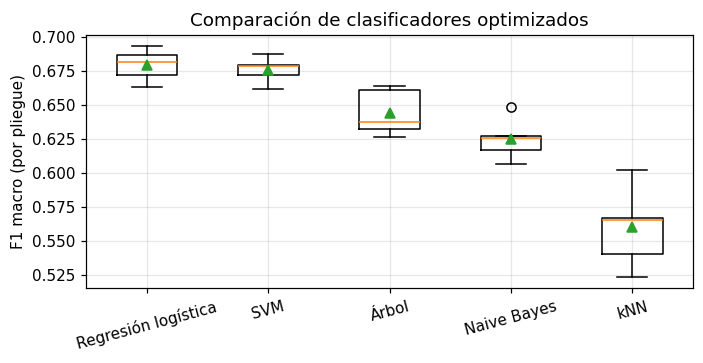

In [ ]:
# Mejores hiperparámetros de cada clasificador
for name, r in RESULTS.items():
    print(f"{name}: " + ", ".join(f"{k.split('__')[-1]}={(type(v).__name__ if hasattr(v, 'get_params') else v)}"
                                  for k, v in r["search"].best_params_.items()))

# F1 macro por pliegue de cada mejor configuración
fold_scores = pd.DataFrame({n: [r["search"].cv_results_[f"split{k}_test_score"][r["search"].best_index_] for k in range(N_FOLDS)]
                            for n, r in RESULTS.items()}, index=[f"pliegue {k+1}" for k in range(N_FOLDS)])
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.boxplot([fold_scores[c] for c in comp.index], showmeans=True)
ax.set_xticks(range(1, len(comp) + 1)); ax.set_xticklabels(comp.index)
ax.set_ylabel("F1 macro (por pliegue)"); ax.set_title("Comparación de clasificadores optimizados")
plt.setp(ax.get_xticklabels(), rotation=15); fig.tight_layout(); fig.savefig(OUT_DIR / "comparacion_boxplot.png"); plt.show()

### Discusión de la comparación

| Clasificador | F1 macro (media ± desv. est.) | Tiempo de búsqueda |
|---|---|---|
| Regresión logística | 0.679 ± 0.011 | 361 s |
| SVM | 0.676 ± 0.008 | 284 s |
| Árbol | 0.644 ± 0.015 | 24 s |
| Naive Bayes | 0.625 ± 0.014 | 13 s |
| kNN | 0.560 ± 0.027 | 30 s |

- **Mejor clasificador:** la regresión logística, pero su ventaja sobre el SVM (0.003) es mucho menor que la desviación estándar entre pliegues (≈ 0.01), así que **estadísticamente están empatados**; la regresión logística es la mejor solo por una diferencia mínima. Ambos superan al árbol (≈ 0.035 más, unas 2.5 a 3 desviaciones estándar), a Naive Bayes y a kNN. Que dos modelos tan distintos (uno lineal y otro con kernel RBF) lleguen al mismo F1 sugiere que la frontera entre clases es casi lineal en estos atributos y que la no linealidad extra del SVM aporta poco.
- **Clase más difícil:** `enrolled`, con sensibilidad de 0.57–0.58 en los tres mejores modelos, 0.49 en Naive Bayes y apenas 0.22 en kNN. Es esperable: es una situación intermedia (ni graduado ni desertor) y además la clase minoritaria. `graduate` es la más fácil (sensibilidad 0.79–0.81 en los mejores) y `dropout` queda en medio (≈ 0.66–0.69), con especificidad alta (≈ 0.92–0.93).
- **kNN** obtiene la mejor sensibilidad de `graduate` (0.873), pero a costa de la peor especificidad (0.582) y de una sensibilidad de `enrolled` de 0.217: tiende a asignar casi todo a la clase mayoritaria. Es el único de los cinco que no admite `class_weight` ni tiene un mecanismo equivalente para compensar el desbalance, y además sufre con la alta dimensionalidad que introduce el one-hot.
- **Naive Bayes** es el que mejor detecta `dropout` (sensibilidad 0.697, ligeramente por encima de la regresión logística), pero con la peor especificidad de esa clase entre los cuatro mejores (0.843): genera más falsas alarmas. Su supuesto de independencia se viola porque los atributos del primer semestre están muy correlacionados.
- **Tiempo:** la regresión logística (saga con elastic net) y el SVM son entre 10 y 25 veces más lentos que el árbol y Naive Bayes, a cambio de ≈ 0.035 a 0.055 de F1 macro. Para un uso real donde se reentrene a menudo, el árbol (0.644 en 24 s) es una alternativa razonable y además interpretable; para obtener la mejor predicción, el costo de la regresión logística es asumible porque solo se entrena una vez.
- **Sesgo de selección:** el F1 de la mejor configuración se eligió en estos mismos pliegues, así que es algo optimista. Sirve para comparar entre clasificadores, pero el F1 de prueba puede quedar un poco por debajo.

## 5. Matriz de confusión del mejor clasificador y análisis de la clase `dropout`

Matriz construida con **predicciones de validación cruzada** (cada estudiante es predicho por un modelo que no lo vio en el ajuste).

Mejor clasificador: Regresión logística


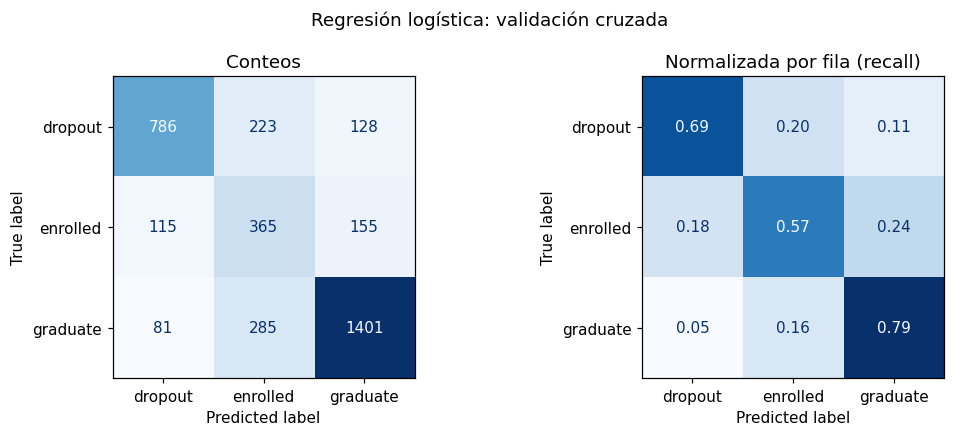


A qué clase se asignan los desertores reales:
col_0    dropout  enrolled  graduate
Target                              
dropout    0.691     0.196     0.113


In [ ]:
best_name = comp.index[0]
y_pred = pd.Series(PRED_CV[best_name], index=y.index)
print("Mejor clasificador:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=LABELS, ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Conteos"); axes[0].grid(False)
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=LABELS, normalize="true", ax=axes[1],
                                        colorbar=False, cmap="Blues", values_format=".2f")
axes[1].set_title("Normalizada por fila (recall)"); axes[1].grid(False)
fig.suptitle(f"{best_name}: validación cruzada"); fig.tight_layout()
fig.savefig(OUT_DIR / "matriz_confusion.png"); plt.show()

print("\nA qué clase se asignan los desertores reales:")
print(pd.crosstab(y[y == "dropout"], y_pred[y == "dropout"], normalize="index").round(3).to_string())

In [ ]:
# ¿Por qué se confunde 'dropout'? Perfil medio de los desertores según lo que predijo el modelo,
# comparado con el de graduados e inscritos reales.
cols_perfil = [c for c in ["Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)",
                           "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
                           "Admission grade", "Age at enrollment", "Tuition fees up to date", "Debtor",
                           "Scholarship holder"] if c in X.columns]
perfil = {}
for pred_cls in LABELS:
    m = (y == "dropout") & (y_pred == pred_cls)
    if m.sum(): perfil[f"dropout predicho {pred_cls} (n={m.sum()})"] = X.loc[m, cols_perfil].mean()
for cls in LABELS:
    if cls != "dropout": perfil[f"{cls} real (n={(y == cls).sum()})"] = X.loc[y == cls, cols_perfil].mean()
perfil = pd.DataFrame(perfil).T
perfil.round(2)

,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Admission grade,Age at enrollment,Tuition fees up to date,Debtor,Scholarship holder
dropout predicho dropout (n=786),5.71,1.64,5.48,0.23,124.40,27.63,0.53,0.28,0.06
dropout predicho enrolled (n=223),5.70,3.60,10.92,0.18,123.85,22.47,0.98,0.12,0.08
dropout predicho graduate (n=128),6.80,6.34,12.57,0.09,129.96,22.84,0.98,0.07,0.34
enrolled real (n=635),6.01,4.33,11.13,0.19,125.34,22.33,0.95,0.11,0.17
graduate real (n=1767),6.68,6.25,12.62,0.09,128.94,21.79,0.99,0.04,0.38


### Análisis de la clase `dropout`

Con la regresión logística, el **69.1 %** de los desertores se detecta correctamente; el **19.6 %** se clasifica como `enrolled` y el **11.3 %** como `graduate`. Es decir, el error principal es confundir al desertor con el inscrito, aunque también hay un grupo importante que parece graduado.

La tabla de perfiles explica por qué:

- **Desertores clasificados correctamente (n = 786):** muestran señales claras de problemas ya en el primer semestre: aprueban en promedio solo 1.6 unidades (de 5.7 inscritas), su promedio es 5.5, solo el 53 % tiene las colegiaturas al corriente, el 28 % es deudor, entran con mayor edad (27.6 años) y casi no tienen beca (6 %).
- **Desertores clasificados como `enrolled` (n = 223):** su perfil es prácticamente el de los inscritos reales: 3.6 unidades aprobadas (frente a 4.3 de los inscritos reales), promedio 10.9 (11.1), 98 % con colegiaturas al corriente (95 %), 12 % deudores (11 %) y edad ≈ 22.5 (22.3). Académica y económicamente no se distinguen de quien sigue inscrito, y la clase `enrolled` es por definición un estado de "aún no terminó ni abandonó".
- **Desertores clasificados como `graduate` (n = 128):** se parecen casi por completo a los graduados reales: 6.3 unidades aprobadas (6.25), promedio 12.6 (12.6), 98 % con colegiaturas al corriente y 34 % con beca (38 %). Son estudiantes con buen primer semestre que abandonan después, probablemente por factores que el dataset no recoge (económicos, familiares, laborales, de salud o cambio de institución).

**Conclusión:** la confusión no es un defecto del modelo sino una limitación de la información disponible. Al cierre del primer semestre, una parte de los desertores todavía no muestra ninguna señal de abandono, y las variables de contexto (padres, nacionalidad, macroeconomía) no bastan para separarlos. Esto fija un techo al F1 alcanzable con solo el primer semestre.

**Implicación práctica:** la sensibilidad de `dropout` (0.69) significa que se deja sin detectar a ≈ 3 de cada 10 desertores, mientras que la especificidad (0.92) indica que ≈ 8 de cada 100 no desertores se marcan como desertores. Si el objetivo es intervenir (tutorías, apoyos económicos), las falsas alarmas cuestan poco comparadas con un desertor no detectado, por lo que podría convenir mover el umbral de decisión para ganar sensibilidad; eso queda fuera de esta práctica.

## 6. ¿Conviene esperar al segundo semestre?

Con el **mejor clasificador y los mismos hiperparámetros**, se compara la validación cruzada (mismos pliegues) usando solo los 30 atributos del primer semestre contra los 36 atributos (primer y segundo semestre). Es una estimación con el conjunto de entrenamiento: en la prueba no existen los atributos del segundo semestre, así que esta variante **no** se usa para el modelo final.

In [ ]:
best_est = RESULTS[best_name]["search"].best_estimator_
f1_1s = cross_val_score(clone(best_est), X,  y, cv=cv, scoring="f1_macro", n_jobs=-1)
f1_2s = cross_val_score(clone(best_est), X2, y, cv=cv, scoring="f1_macro", n_jobs=-1)
diff = f1_2s - f1_1s
pred_2s = cross_val_predict(clone(best_est), X2, y, cv=cv, n_jobs=-1)

tab = pd.DataFrame({
    "F1 macro media": [f1_1s.mean(), f1_2s.mean()],
    "F1 macro desv. est.": [f1_1s.std(ddof=1), f1_2s.std(ddof=1)],
    **{f"sens_{l}": [sens_spec(y, PRED_CV[best_name], LABELS)[f"sens_{l}"], sens_spec(y, pred_2s, LABELS)[f"sens_{l}"]] for l in LABELS},
}, index=["Cierre 1.er semestre (30 atributos)", "Cierre 2.º semestre (36 atributos)"])
display(tab.round(3))
print(f"Mejora en F1 macro: {diff.mean():+.4f} (desv. est. de la diferencia entre pliegues: {diff.std(ddof=1):.4f}; "
      f"el 2.º semestre gana en {(diff > 0).sum()} de {N_FOLDS} pliegues)")
tab.round(4).to_csv(OUT_DIR / "primer_vs_segundo_semestre.csv")

,F1 macro media,F1 macro desv. est.,sens_dropout,sens_enrolled,sens_graduate
Cierre 1.er semestre (30 atributos),0.679,0.012,0.691,0.575,0.793
Cierre 2.º semestre (36 atributos),0.712,0.007,0.726,0.609,0.823


Mejora en F1 macro: +0.0328 (desv. est. de la diferencia entre pliegues: 0.0179; el 2.º semestre gana en 5 de 5 pliegues)


### ¿Conviene esperar al segundo semestre?

Con la regresión logística y los mismos hiperparámetros, el F1 macro pasa de **0.679 ± 0.012** (30 atributos) a **0.712 ± 0.007** (36 atributos): una mejora de **+0.033**, con una desviación estándar de la diferencia entre pliegues de 0.018. El segundo semestre gana en los **5 de 5 pliegues**, así que la mejora es consistente, aunque modesta y de magnitud solo ≈ 1.8 desviaciones estándar de la diferencia. La sensibilidad sube en las tres clases: `dropout` de 0.691 a 0.726 (+0.035), `enrolled` de 0.575 a 0.609 (+0.034) y `graduate` de 0.793 a 0.823 (+0.030). Es una mejora repartida, no concentrada en una clase.

**¿Conviene esperar?** Con estos números, probablemente no, si el propósito es intervenir a tiempo:

- La ganancia (≈ 3 puntos de F1 macro) es pequeña frente al costo de esperar un semestre completo, tiempo en el que los desertores que se habrían detectado ya habrían abandonado o seguirían sin apoyo. Aun con el segundo semestre, cerca del 27 % de los desertores seguiría sin detectarse.
- Parte de la mejora puede no ser predicción sino observación: al cierre del segundo semestre algunos estudiantes ya abandonaron, y eso se refleja en unidades inscritas o evaluadas en cero; el modelo detectaría lo que ya ocurrió.
- Esperar tendría sentido si el costo de intervenir es alto y solo se quiere actuar con mayor certeza. Una estrategia intermedia sería usar el modelo del primer semestre para marcar a los de mayor riesgo desde el principio y esperar al segundo solo para los casos dudosos.
- Además, estos 36 atributos no existen en el archivo de prueba, así que el modelo final usa únicamente el primer semestre.

## 7. Clasificador final y predicciones de prueba

El mejor clasificador (según F1 macro de validación cruzada) se reentrena con **todo el conjunto de entrenamiento** y solo con los atributos del primer semestre, que son los que existen en la prueba.

In [ ]:
final_model = clone(RESULTS[best_name]["search"].best_estimator_).fit(X, y)
print("Clasificador final:", best_name)

X_test = test[FEATURES_1S]
pred_test = final_model.predict(X_test)

submission = pd.DataFrame({"id": test["id"].to_numpy(), "Target": pd.Series(pred_test).str.lower().to_numpy()})
assert list(submission.columns) == ["id", "Target"]
assert len(submission) == len(test) and submission["id"].is_unique
assert set(submission["Target"]) <= {"dropout", "enrolled", "graduate"}
if len(submission) != 885: print(f"AVISO: se esperaban 885 filas y hay {len(submission)}.")

submission.to_csv(PRED_CSV, index=False)
print(f"Guardado: {PRED_CSV} ({len(submission)} filas)")
print(submission["Target"].value_counts(normalize=True).round(3).to_string())
submission.head()

Clasificador final: Regresión logística
Guardado: predicciones.csv (885 filas)
Target
graduate    0.475
enrolled    0.264
dropout     0.261


,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


## 8. Discusión y conclusiones

**Por clasificador**

- **Árbol de decisión (F1 macro 0.644 ± 0.015; 24 s).** Necesitó poda moderada y profundidad limitada (profundidad 6, `ccp_alpha` ≈ 5e-4, `min_samples_leaf` = 29) y se benefició de `class_weight="balanced"`. Es el más interpretable y rápido de los modelos que rinden razonablemente, pero queda ≈ 0.035 por debajo de los dos mejores y tiene mayor varianza entre pliegues: un solo árbol es inestable ante pequeños cambios en los datos.
- **Naive Bayes (0.625 ± 0.014; 13 s).** Ganó la variante categórica con numéricos discretizados, sin priors (`fit_prior=False`), lo que compensa en parte el desbalance. Es el más rápido y el mejor detectando `dropout` (sensibilidad 0.697), pero con más falsas alarmas (especificidad 0.843). Su supuesto de independencia condicional no se cumple, lo que limita su techo.
- **kNN (0.560 ± 0.027; 30 s).** Es el peor clasificador. Prefiere `k` pequeño (5) y ponderación por distancia, y casi no reconoce a `enrolled` (sensibilidad 0.217): predice con demasiada frecuencia la clase mayoritaria. Con 30 atributos y varias decenas de columnas one-hot, las distancias pierden capacidad discriminativa, y no tiene forma de ponderar las clases.
- **SVM (0.676 ± 0.008; 284 s).** Segundo mejor y el más estable entre pliegues. Ganó el kernel RBF con `C` ≈ 1.6 y `class_weight="balanced"`. Su rendimiento prácticamente empata con el de la regresión logística, pero es mucho más costoso de ajustar y menos interpretable.
- **Regresión logística (0.679 ± 0.011; 361 s).** El mejor, con regularización elastic net (`l1_ratio` = 0.7, `C` ≈ 0.14) y `class_weight="balanced"`. Que un modelo lineal regularizado alcance (y apenas supere) al SVM RBF indica que el problema es casi linealmente separable en estos atributos, y la elección de una mezcla con L1 es compatible con que varios atributos aporten poco (habría que revisar los coeficientes para confirmarlo). Además, sus coeficientes son interpretables.

**Conclusiones globales**

1. Se elige la **regresión logística** como clasificador final. La diferencia con el SVM no es significativa, por lo que se prefiere la regresión logística por ser más simple e interpretable, y de rendimiento al menos igual.
2. Los modelos lineales y el SVM superan claramente a los demás. Los dos mecanismos que más ayudaron fueron la **regularización adecuada** y el **balanceo de clases**: los tres clasificadores que admiten `class_weight` lo eligieron balanceado, y el kNN, que no lo admite, es el que peor desempeño tuvo con `enrolled`.
3. `enrolled` es la clase más difícil (sensibilidad ≈ 0.58 en los mejores modelos), por ser un estado intermedio y minoritario. `dropout` se confunde sobre todo con `enrolled` y, en menor medida, con `graduate`, porque parte de los desertores no muestra señales de abandono en el primer semestre.
4. Esperar al segundo semestre mejoraría el F1 macro en ≈ 0.033 (0.679 → 0.712), de forma consistente pero modesta; no parece compensar la pérdida de un semestre para intervenir.
5. La distribución de las predicciones sobre la prueba (47.5 % `graduate`, 26.4 % `enrolled` y 26.1 % `dropout`) difiere de la del entrenamiento (49.9 %, 17.9 % y 32.1 %): el modelo predice más `enrolled` y menos `dropout` que su frecuencia real en entrenamiento. Es coherente con `class_weight="balanced"`, que privilegia el recall de las clases minoritarias, pero no podemos saber si la prueba tiene la misma distribución.

**Limitaciones**

- El F1 macro de validación cruzada de la mejor configuración se eligió en esos mismos pliegues, por lo que es algo optimista; el F1 de prueba puede ser un poco menor.
- **kNN:** 15 de sus 60 configuraciones fallaron (el `RandomizedSearchCV` usa `error_score=np.nan`, que oculta el error), de modo que solo tiene 45 configuraciones válidas, por debajo de las 50 que pide la práctica. No se investigó la causa; no afecta la elección del mejor clasificador porque kNN queda muy por debajo, pero habría que revisarlo: con `error_score="raise"` en `RandomizedSearchCV` se vería el mensaje de error, o se puede inspeccionar `pd.DataFrame(RESULTS["kNN"]["search"].cv_results_)` filtrando las filas con `mean_test_score` nulo.
- Datos de una sola institución y periodo; los resultados pueden no generalizar a otros contextos.
- No se evaluaron ensambles ni redes neuronales, por restricción de la práctica; un ensamble de árboles podría superar a estos modelos, pero no se probó.
- No se ajustó el umbral de decisión ni se asignaron costos distintos a cada tipo de error, algo relevante si el modelo se usara para intervenir.

## Declaración y uso de IA
Se utilizó el modelo de Sonnet 5.5 para sugerir y corregir código, así como correción de gramática y ortografía.